# EN3330 – Assignment 03 220386H
**Lagrangian, dual function, saddle point and weak duality**

Problem:
$$\min_x \; x^2 \quad \text{subject to} \quad x \ge 1 \qquad \big(h(x) = 1 - x \le 0\big)$$

Lagrangian:
$$L(\mu, x) = x^2 + \mu(1 - x), \qquad \mu \ge 0$$

This notebook produces every plot used in the answer script and checks the analytical answers numerically.
Plots are also saved as PNG files in the `fig/` folder.

In [13]:
import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

os.makedirs("fig", exist_ok=True)
plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3, "savefig.bbox": "tight",
                     "savefig.dpi": 300, "figure.dpi": 110})
C = ["#1f4e79", "#2e8b57", "#c0392b", "#d68910", "#7d3c98", "#555555"]

def L(mu, x):
    # Lagrangian L(mu, x) = x^2 + mu(1 - x)
    return x**2 + mu * (1 - x)

x = np.linspace(-1, 3, 500)          # x range used for the plots
xs = np.linspace(-5, 5, 200001)      # fine grid for numerical checks

## Question 1(a) – $L(\mu, x)$ for $\mu = 0, 1, 2, 3$

Setting $\partial L/\partial x = 2x - \mu = 0$ gives the minimiser $x(\mu) = \mu/2$,
with minimum value $L(\mu, x(\mu)) = \mu - \mu^2/4$.

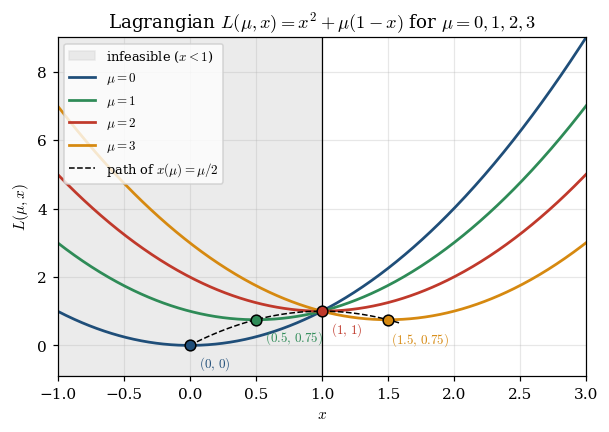

In [14]:
fig, ax = plt.subplots(figsize=(6.2, 4.0))
ax.axvspan(-1, 1, color="0.85", alpha=0.5, label="infeasible ($x<1$)")
for i, mu in enumerate([0, 1, 2, 3]):
    ax.plot(x, L(mu, x), color=C[i], lw=1.8, label=fr"$\mu={mu}$")
    xm = mu / 2
    ax.plot(xm, L(mu, xm), "o", color=C[i], ms=7, mec="k", zorder=5)
    ax.annotate(fr"$({xm:g},\,{L(mu, xm):g})$", (xm, L(mu, xm)), textcoords="offset points",
                xytext=(6, -14) if mu != 3 else (2, -15), fontsize=8.5, color=C[i])
t = np.linspace(0, 1.6, 100)
ax.plot(t, 2*t - t**2, "k--", lw=1, label=r"path of $x(\mu)=\mu/2$")
ax.axvline(1, color="k", lw=0.8)
ax.set_xlabel("$x$"); ax.set_ylabel(r"$L(\mu,x)$")
ax.set_xlim(-1, 3); ax.set_ylim(-0.9, 9)
ax.set_title(r"Lagrangian $L(\mu,x)=x^2+\mu(1-x)$ for $\mu=0,1,2,3$")
ax.legend(fontsize=8.5, loc="upper left")
fig.savefig("fig/Q1a_Lagrangian_vs_x.png")
plt.show()

In [15]:
# Numerical check: grid-search minimiser vs analytic x(mu) = mu/2
print(" mu | x(mu) grid | x(mu)=mu/2 | min L grid | mu - mu^2/4")
for mu in [0, 1, 2, 3]:
    v = L(mu, xs); i = v.argmin()
    print(f" {mu:2d} | {xs[i]:10.4f} | {mu/2:10.4f} | {v[i]:10.4f} | {mu - mu**2/4:10.4f}")

 mu | x(mu) grid | x(mu)=mu/2 | min L grid | mu - mu^2/4
  0 |     0.0000 |     0.0000 |     0.0000 |     0.0000
  1 |     0.5000 |     0.5000 |     0.7500 |     0.7500
  2 |     1.0000 |     1.0000 |     1.0000 |     1.0000
  3 |     1.5000 |     1.5000 |     0.7500 |     0.7500


## Question 1(b) – Dual function

$$d(\mu) = \min_x L(\mu, x) = \mu - \frac{\mu^2}{4}, \qquad
d'(\mu) = 1 - \frac{\mu}{2} = 0 \;\Rightarrow\; \mu^* = 2,\; d^* = 1$$

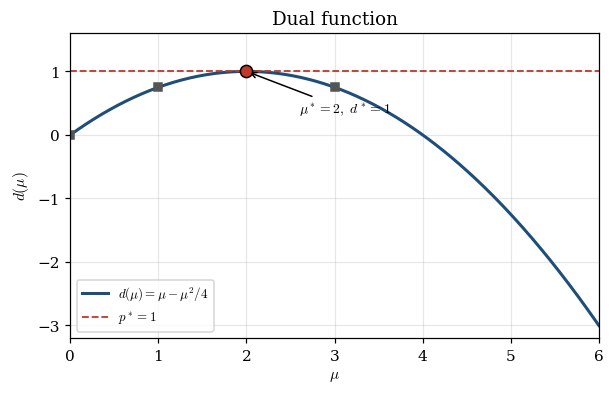

In [16]:
mu = np.linspace(0, 6, 400)
d = mu - mu**2 / 4

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.plot(mu, d, color=C[0], lw=2, label=r"$d(\mu)=\mu-\mu^2/4$")
ax.axhline(1, color=C[2], ls="--", lw=1.2, label=r"$p^*=1$")
for m in [0, 1, 3]:
    ax.plot(m, m - m**2/4, "s", color=C[5], ms=5)
ax.plot(2, 1, "o", color=C[2], ms=8, mec="k", zorder=5)
ax.annotate(r"$\mu^*=2,\ d^*=1$", (2, 1), xytext=(2.6, 0.35),
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_xlabel(r"$\mu$"); ax.set_ylabel(r"$d(\mu)$")
ax.set_xlim(0, 6); ax.set_ylim(-3.2, 1.6)
ax.set_title("Dual function"); ax.legend(fontsize=8.5, loc="lower left")
fig.savefig("fig/Q1b_dual_function.png")
plt.show()

In [17]:
# Numerical check: maximise d(mu) on a grid
mus = np.linspace(0, 10, 100001)
dv = mus - mus**2 / 4
print(f"mu* = {mus[dv.argmax()]:.4f},  d* = {dv.max():.4f}   (p* = 1, so the duality gap is {1 - dv.max():.4f})")

mu* = 2.0000,  d* = 1.0000   (p* = 1, so the duality gap is 0.0000)


## Question 1(c) – Primal function $g(x) = \max_{\mu \ge 0} L(\mu, x)$

For fixed $x$, $L$ is a straight line in $\mu$ with slope $1 - x$:

$$g(x) = \begin{cases} x^2, & x \ge 1 \text{ (feasible)} \\ +\infty, & x < 1 \text{ (infeasible)} \end{cases}$$

The plot shows $L(\mu, x)$ for increasing $\mu$: to the left of $x = 1$ the curves rise without bound, to the right the largest is the $\mu = 0$ curve $x^2$.

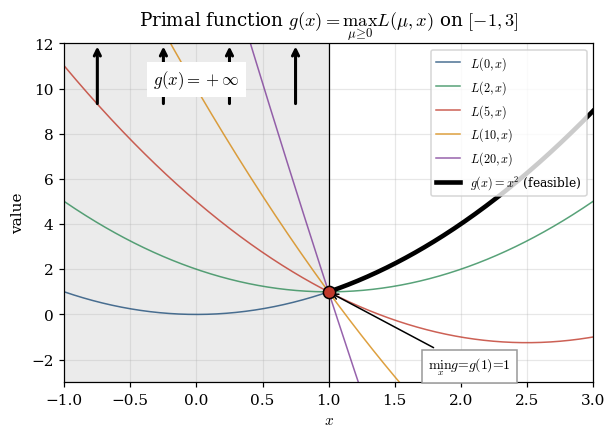

In [18]:
fig, ax = plt.subplots(figsize=(6.2, 4.0))
ax.axvspan(-1, 1, color="0.85", alpha=0.5)
for i, m in enumerate([0, 2, 5, 10, 20]):
    ax.plot(x, L(m, x), color=C[i], lw=1, alpha=0.8, label=fr"$L({m},x)$")
xf = x[x >= 1]
ax.plot(xf, xf**2, color="k", lw=3, label=r"$g(x)=x^2$ (feasible)")
for xa in [-0.75, -0.25, 0.25, 0.75]:
    ax.annotate("", xy=(xa, 12), xytext=(xa, 9.2), arrowprops=dict(arrowstyle="->", lw=2, color="k"))
ax.text(0, 10.2, r"$g(x)=+\infty$", ha="center", fontsize=11, bbox=dict(fc="w", ec="none"))
ax.plot(1, 1, "o", color=C[2], ms=8, mec="k", zorder=6)
ax.annotate(r"$\min_x g=g(1)=1$", (1, 1), xytext=(1.75, -2.4),
            arrowprops=dict(arrowstyle="->"), fontsize=9, bbox=dict(fc="w", ec="0.6"))
ax.axvline(1, color="k", lw=0.8)
ax.set_xlabel("$x$"); ax.set_ylabel("value")
ax.set_xlim(-1, 3); ax.set_ylim(-3, 12)
ax.set_title(r"Primal function $g(x)=\max_{\mu\geq0}L(\mu,x)$ on $[-1,3]$")
ax.legend(fontsize=8, loc="upper right")
fig.savefig("fig/Q1c_primal_function.png")
plt.show()

In [19]:
# Numerical check: approximate max over mu with a very large mu
for x0 in [-1, 0, 0.5, 1, 2, 3]:
    g = max(L(m, x0) for m in [0, 1e2, 1e4, 1e6])
    print(f"x = {x0:4}:  max_mu L ~ {g:.4g}   (x^2 = {x0**2})")

x =   -1:  max_mu L ~ 2e+06   (x^2 = 1)
x =    0:  max_mu L ~ 1e+06   (x^2 = 0)
x =  0.5:  max_mu L ~ 5e+05   (x^2 = 0.25)
x =    1:  max_mu L ~ 1   (x^2 = 1)
x =    2:  max_mu L ~ 4   (x^2 = 4)
x =    3:  max_mu L ~ 9   (x^2 = 9)


## Question 2(a)(iv) – Saddle point at $(x^*, \mu^*) = (1, 2)$

$$L(\mu, x^*) = 1 \;\;\text{(independent of } \mu), \qquad L(\mu^*, x) = (x - 1)^2 + 1, \qquad L(\mu^*, x^*) = 1$$

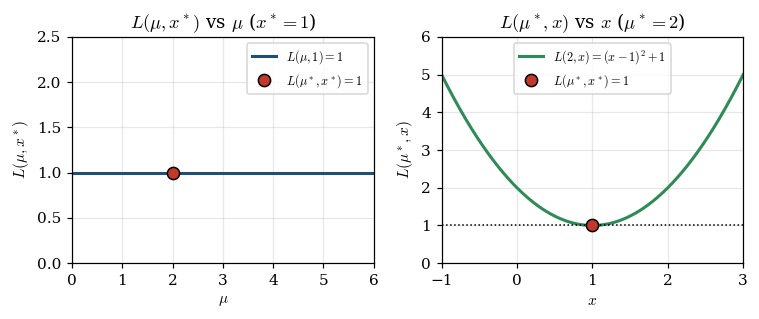

In [20]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.0, 3.0))

m = np.linspace(0, 6, 100)
a1.plot(m, np.ones_like(m), color=C[0], lw=2, label=r"$L(\mu,1)=1$")
a1.plot(2, 1, "o", color=C[2], ms=8, mec="k", zorder=5, label=r"$L(\mu^*,x^*)=1$")
a1.set_xlabel(r"$\mu$"); a1.set_ylabel(r"$L(\mu,x^*)$")
a1.set_ylim(0, 2.5); a1.set_xlim(0, 6)
a1.set_title(r"$L(\mu,x^*)$ vs $\mu$ ($x^*=1$)"); a1.legend(fontsize=8)

a2.plot(x, (x - 1)**2 + 1, color=C[1], lw=2, label=r"$L(2,x)=(x-1)^2+1$")
a2.axhline(1, color="k", ls=":", lw=1)
a2.plot(1, 1, "o", color=C[2], ms=8, mec="k", zorder=5, label=r"$L(\mu^*,x^*)=1$")
a2.set_xlabel("$x$"); a2.set_ylabel(r"$L(\mu^*,x)$")
a2.set_xlim(-1, 3); a2.set_ylim(0, 6)
a2.set_title(r"$L(\mu^*,x)$ vs $x$ ($\mu^*=2$)"); a2.legend(fontsize=8, loc="upper center")

fig.tight_layout()
fig.savefig("fig/Q2a_iv_saddle_point.png")
plt.show()

In [21]:
# Numerical check of both saddle-point inequalities
print("L(mu*, x*)                    =", L(2, 1))
print("max over mu of L(mu, x*) - L* =", max(L(m, 1) for m in mus) - L(2, 1), " (<= 0: left inequality)")
print("min over x  of L(mu*, x) - L* =", L(2, xs).min() - L(2, 1), " (>= 0: right inequality)")

L(mu*, x*)                    = 1
max over mu of L(mu, x*) - L* = 0.0  (<= 0: left inequality)
min over x  of L(mu*, x) - L* = 0.0  (>= 0: right inequality)


## Question 2(c) – Modified constraint $x \ge -1$ (optional plot)

$h(x) = -1 - x$, so $d(\mu) = -\mu - \mu^2/4$, which is largest at $\mu^* = 0$ (inactive constraint).

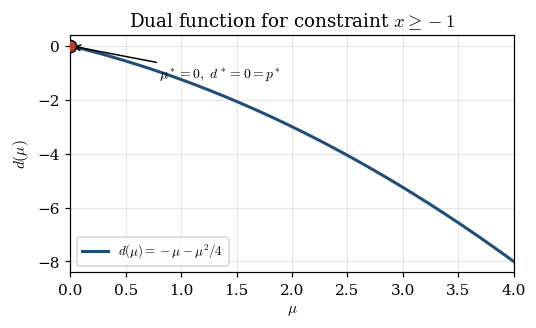

mu* (grid) = 0.0


In [22]:
m = np.linspace(0, 4, 200)
fig, ax = plt.subplots(figsize=(5.2, 2.8))
ax.plot(m, -m - m**2/4, color=C[0], lw=2, label=r"$d(\mu)=-\mu-\mu^2/4$")
ax.plot(0, 0, "o", color=C[2], ms=8, mec="k", zorder=5)
ax.annotate(r"$\mu^*=0,\ d^*=0=p^*$", (0, 0), xytext=(0.8, -1.2),
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_xlabel(r"$\mu$"); ax.set_ylabel(r"$d(\mu)$"); ax.set_xlim(0, 4)
ax.set_title(r"Dual function for constraint $x\geq-1$")
ax.legend(fontsize=8.5, loc="lower left")
fig.savefig("fig/Q2c_dual_x_ge_-1.png")
plt.show()

print("mu* (grid) =", mus[np.argmax(-mus - mus**2/4)])

## Question 3(a) – Weak duality check: $d(\mu) \le p^* = 1$

In [23]:
print(" mu | d(mu) | d(mu) <= p* ? | gap p* - d(mu)")
for mu in [0, 1, 2, 3]:
    d = mu - mu**2 / 4
    print(f" {mu:2d} | {d:5.2f} | {str(d <= 1):>13} | {1 - d:.2f}")

 mu | d(mu) | d(mu) <= p* ? | gap p* - d(mu)
  0 |  0.00 |          True | 1.00
  1 |  0.75 |          True | 0.25
  2 |  1.00 |          True | 0.00
  3 |  0.75 |          True | 0.25


## Question 3(b) – $L(\mu, x)$ as lines in $\mu$ and their lower envelope

$$x = 0: L = \mu, \qquad x = 1: L = 1, \qquad x = 2: L = 4 - \mu$$

The lower envelope $\min\{\mu, 1, 4 - \mu\}$ is concave and approximates $d(\mu) = \mu - \mu^2/4$ from above.

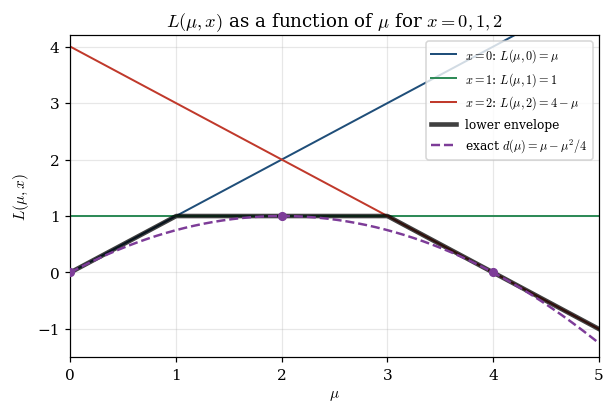

In [24]:
m = np.linspace(0, 5, 500)
lines = {0: m, 1: np.ones_like(m), 2: 4 - m}
labels = [r"\mu", "1", r"4-\mu"]

fig, ax = plt.subplots(figsize=(6.2, 3.8))
for i, (xx, v) in enumerate(lines.items()):
    ax.plot(m, v, color=C[i], lw=1.3, label=fr"$x={xx}$: $L(\mu,{xx})={labels[i]}$")
env = np.minimum.reduce(list(lines.values()))
ax.plot(m, env, color="k", lw=3, alpha=0.75, label="lower envelope")
ax.plot(m, m - m**2/4, "--", color=C[4], lw=1.6, label=r"exact $d(\mu)=\mu-\mu^2/4$")
for mm, vv in [(0, 0), (2, 1), (4, 0)]:
    ax.plot(mm, vv, "o", color=C[4], ms=5, zorder=6)
ax.set_xlabel(r"$\mu$"); ax.set_ylabel(r"$L(\mu,x)$")
ax.set_xlim(0, 5); ax.set_ylim(-1.5, 4.2)
ax.set_title(r"$L(\mu,x)$ as a function of $\mu$ for $x=0,1,2$")
ax.legend(fontsize=8, loc="upper right")
fig.savefig("fig/Q3b_lines_lower_envelope.png")
plt.show()